<a href="https://colab.research.google.com/github/davinjmatias/IT480-FA26/blob/main/Assignment2_TransferLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2: Transfer Learning Across Two Datasets

**Name:** *Davin Matias*

**Prerequisite:** Transfer Learning lecture (frozen feature extraction)

This assignment uses frozen transfer learning, exactly what was covered in lecture: load a pretrained base, freeze it, add a new head, train only that. You'll do this twice, on two different datasets, and compare the results.

Data loading is provided for you below. Everything after that, building the model, training, evaluating, and reflecting, is yours to write, following the general instructions in each section.

**Submission:** GitHub repo URL and this notebook's URL on Canvas.

## Setup — Imports

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

---
# Part 1: Fire/Smoke Detection

## 1A — Load the Data

In [2]:
!pip install legacy-cgi --quiet
!pip install opendatasets --quiet

import opendatasets as od
od.download("https://www.kaggle.com/datasets/phylake1337/fire-dataset")

for root, dirs, files in os.walk("fire-dataset"):
    print(root, "->", dirs[:5], f"({len(files)} files)")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: davinmatias
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/phylake1337/fire-dataset


100%|██████████| 387M/387M [00:06<00:00, 65.8MB/s]



fire-dataset -> ['fire_dataset'] (0 files)
fire-dataset/fire_dataset -> ['fire_images', 'non_fire_images'] (0 files)
fire-dataset/fire_dataset/fire_images -> [] (755 files)
fire-dataset/fire_dataset/non_fire_images -> [] (244 files)


In [3]:
data_dir_fire = "fire-dataset/fire_dataset"

img_size = (224, 224)
batch_size = 32

train_raw_fire = tf.keras.utils.image_dataset_from_directory(
    data_dir_fire, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="training", seed=42, shuffle=True
)

val_test_raw_fire = tf.keras.utils.image_dataset_from_directory(
    data_dir_fire, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="validation", seed=42, shuffle=True
)

val_test_batches_fire = tf.data.experimental.cardinality(val_test_raw_fire)
test_raw_fire = val_test_raw_fire.take(val_test_batches_fire // 2)
val_raw_fire = val_test_raw_fire.skip(val_test_batches_fire // 2)

class_names_fire = train_raw_fire.class_names
print("Class names:", class_names_fire)

Found 999 files belonging to 2 classes.
Using 700 files for training.
Found 999 files belonging to 2 classes.
Using 299 files for validation.
Class names: ['fire_images', 'non_fire_images']


## 1B — Inspect the Data

Before doing anything else, take a real look at what you loaded. How many images does each class have? Is there anything about the data itself that might affect how you should split it, or how you should interpret your model's results later?

Write whatever code you need to answer this for yourself.

In [4]:
# Count files per class in the dataset directory to inspect the balance
for class_name in class_names_fire:
    class_path = os.path.join(data_dir_fire, class_name)
    num_images = len(os.listdir(class_path))
    print(f"{class_name}: {num_images} images")

fire_images: 755 images
non_fire_images: 244 images


In [5]:
import os
# Count files per class
for class_name in class_names_fire:
    class_path = os.path.join(data_dir_fire, class_name)
    num_images = len(os.listdir(class_path))
    print(f"{class_name}: {num_images} images")

fire_images: 755 images
non_fire_images: 244 images


*What did you notice about this dataset? Does it change how you'll approach the next steps?*



**This dataset is unbalanced. There are significantly more fire_images than non_fire_images. The dataset must be scaled in order to weigh both classes equally.**

## 1C — Build a Frozen Transfer Learning Model

Using MobileNetV2 as your pretrained base:
- Freeze the base model entirely
- Add a new output layer appropriate for this task (think about how many classes you're predicting, and what that means for your output layer's size, activation, and loss function)
- Remember the pattern from lecture for how the base model should be called

Preprocess your data (`train_raw_fire`, `val_raw_fire`, `test_raw_fire`) using MobileNetV2's expected preprocessing before building your model.

In [6]:
# Preprocess the data using MobileNetV2's expected preprocessing
def preprocess_dataset(ds):
    return ds.map(lambda x, y: (preprocess_input(x), y))

train_fire = preprocess_dataset(train_raw_fire).prefetch(buffer_size=tf.data.AUTOTUNE)
val_fire = preprocess_dataset(val_raw_fire).prefetch(buffer_size=tf.data.AUTOTUNE)
test_fire = preprocess_dataset(test_raw_fire).prefetch(buffer_size=tf.data.AUTOTUNE)

In [7]:
# Apply MobileNetV2 preprocessing to our datasets
def preprocess_dataset(ds):
    return ds.map(lambda x, y: (preprocess_input(x), y))

train_fire = preprocess_dataset(train_raw_fire).prefetch(buffer_size=tf.data.AUTOTUNE)
val_fire = preprocess_dataset(val_raw_fire).prefetch(buffer_size=tf.data.AUTOTUNE)
test_fire = preprocess_dataset(test_raw_fire).prefetch(buffer_size=tf.data.AUTOTUNE)

In [8]:
# Load MobileNetV2 base
base_model_fire = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model_fire.trainable = False

# Create model architecture
inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model_fire(inputs, training=False)
x = GlobalAveragePooling2D()(x)
outputs = Dense(1, activation='sigmoid')(x)  # Binary classification

model_fire = Model(inputs, outputs)
model_fire.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
# Load MobileNetV2 base
base_model_fire = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model_fire.trainable = False

# Create model architecture
inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model_fire(inputs, training=False)
x = GlobalAveragePooling2D()(x)
outputs = Dense(1, activation='sigmoid')(x) # Binary classification: fire vs non-fire

model_fire = Model(inputs, outputs)
model_fire.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
# Compile model with binary crossentropy
model_fire.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [11]:
model_fire.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## 1D — Train and Evaluate

In [12]:
# Train the fire/smoke detection model
history_fire = model_fire.fit(
    train_fire,
    epochs=10,
    validation_data=val_fire
)

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.8257 - loss: 0.3467 - val_accuracy: 0.9281 - val_loss: 0.2380
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.9543 - loss: 0.1471 - val_accuracy: 0.9568 - val_loss: 0.1268
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - accuracy: 0.9743 - loss: 0.0999 - val_accuracy: 0.9568 - val_loss: 0.1033
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - accuracy: 0.9786 - loss: 0.0807 - val_accuracy: 0.9784 - val_loss: 0.0797
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.9843 - loss: 0.0692 - val_accuracy: 0.9784 - val_loss: 0.0726
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.9886 - loss: 0.0612 - val_accuracy: 0.9712 - val_loss: 0.0861
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 85s 2s/step - accuracy: 0.9900 - loss: 0.0544 - val_accuracy: 0.9640 - val_loss: 0.0889
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.9929 - loss: 0.0501 - val_accuracy: 0.9856 - val_loss:

In [13]:
history_fire = model_fire.fit(
    train_fire,
    epochs=10,
    validation_data=val_fire
)

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.9957 - loss: 0.0395 - val_accuracy: 0.9856 - val_loss: 0.0544
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - accuracy: 0.9971 - loss: 0.0360 - val_accuracy: 0.9856 - val_loss: 0.0620
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - accuracy: 0.9971 - loss: 0.0344 - val_accuracy: 0.9856 - val_loss: 0.0583
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.9971 - loss: 0.0320 - val_accuracy: 0.9784 - val_loss: 0.0648
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accuracy: 0.9971 - loss: 0.0304 - val_accuracy: 0.9640 - val_loss: 0.0980
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.9971 - loss: 0.0286 - val_accuracy: 0.9712 - val_loss: 0.0856
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.9986 - loss: 0.0271 - val_accuracy: 0.9928 - val_loss: 0.0464
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.9986 - loss: 0.0256 - val_accuracy: 0.9856 - val_loss:

In [14]:
# Evaluate and display model accuracy
val_loss, val_acc = model_fire.evaluate(val_fire, verbose=0)
test_loss, test_acc = model_fire.evaluate(test_fire, verbose=0)
print(f"Fire Model - Validation Accuracy: {val_acc:.4f}")
print(f"Fire Model - Test Accuracy: {test_acc:.4f}")

Fire Model - Validation Accuracy: 0.9856
Fire Model - Test Accuracy: 0.9875


In [15]:
val_loss, val_acc = model_fire.evaluate(val_fire)
test_loss, test_acc = model_fire.evaluate(test_fire)
print(f"Fire Model - Validation Accuracy: {val_acc:.4f}")
print(f"Fire Model - Test Accuracy: {test_acc:.4f}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.9712 - loss: 0.0763
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.9750 - loss: 0.0725
Fire Model - Validation Accuracy: 0.9712
Fire Model - Test Accuracy: 0.9750


## 1E — Confusion Matrix and Discussion

Build a confusion matrix for your model's test set predictions.

**Answer:** In this context, is a false negative (missing a real fire) or a false positive (a false alarm) more costly? How might that change the decision threshold you'd actually use in practice, rather than the default 0.5?

**A false negative is significantly more costly than a false positive in the context of a real fire. Because of the severity of a possible wild fire, the decision threshold would more realistically be lower than 0.5 in order to have more false positives than false negatives.**

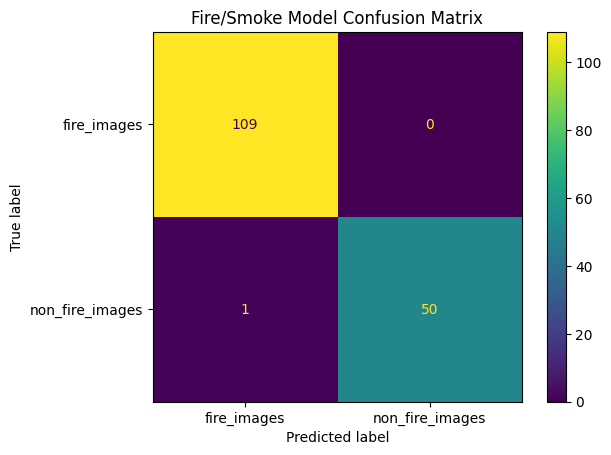

In [16]:
# Compute predictions and generate confusion matrix
y_true = []
y_pred = []

for x, y in test_fire:
    preds = model_fire.predict(x, verbose=0)
    y_true.extend(y.numpy())
    y_pred.extend((preds > 0.5).astype(int).flatten())

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names_fire)
disp.plot()
plt.title("Fire/Smoke Model Confusion Matrix")
plt.show()

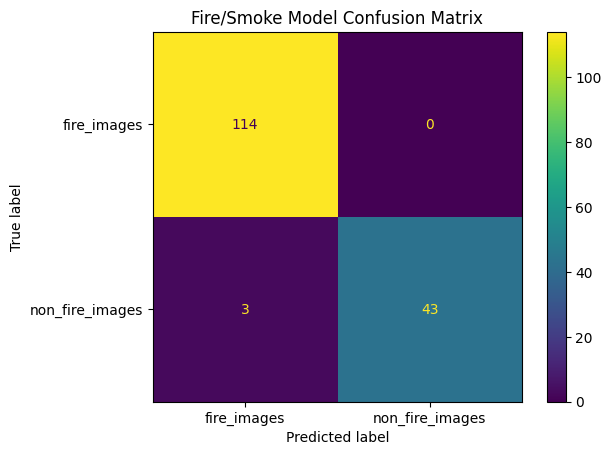

In [17]:
y_true = []
y_pred = []

for x, y in test_fire:
    preds = model_fire.predict(x, verbose=0)
    y_true.extend(y.numpy())
    y_pred.extend((preds > 0.5).astype(int).flatten())

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names_fire)
disp.plot()
plt.title("Fire/Smoke Model Confusion Matrix")
plt.show()

*Your answer:*




---
# Part 2: Satellite Land-Use Classification (EuroSAT)

## 2A — Load the Data

In [18]:
!wget -q "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1" -O EuroSAT_RGB.zip
!unzip -q EuroSAT_RGB.zip -d eurosat_data

data_dir_sat = "eurosat_data/EuroSAT_RGB"
print(os.listdir(data_dir_sat))

['Pasture', 'SeaLake', 'HerbaceousVegetation', 'Residential', 'Industrial', 'AnnualCrop', 'River', 'Highway', 'Forest', 'PermanentCrop']


In [19]:
train_raw_sat = tf.keras.utils.image_dataset_from_directory(
    data_dir_sat, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="training", seed=42, shuffle=True
)

val_test_raw_sat = tf.keras.utils.image_dataset_from_directory(
    data_dir_sat, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="validation", seed=42, shuffle=True
)

val_test_batches_sat = tf.data.experimental.cardinality(val_test_raw_sat)
test_raw_sat = val_test_raw_sat.take(val_test_batches_sat // 2)
val_raw_sat = val_test_raw_sat.skip(val_test_batches_sat // 2)

class_names_sat = train_raw_sat.class_names
print("Class names:", class_names_sat)

Found 27000 files belonging to 10 classes.
Using 18900 files for training.
Found 27000 files belonging to 10 classes.
Using 8100 files for validation.
Class names: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


## 2B — Build a Frozen Transfer Learning Model

Same overall pattern as Part 1, but look closely at what's different about this task before you build your output layer, activation, and loss function.

Preprocess `train_raw_sat`, `val_raw_sat`, and `test_raw_sat` first.

In [20]:
# Preprocess EuroSAT datasets
train_sat = preprocess_dataset(train_raw_sat).prefetch(buffer_size=tf.data.AUTOTUNE)
val_sat = preprocess_dataset(val_raw_sat).prefetch(buffer_size=tf.data.AUTOTUNE)
test_sat = preprocess_dataset(test_raw_sat).prefetch(buffer_size=tf.data.AUTOTUNE)

In [21]:
train_sat = preprocess_dataset(train_raw_sat).prefetch(buffer_size=tf.data.AUTOTUNE)
val_sat = preprocess_dataset(val_raw_sat).prefetch(buffer_size=tf.data.AUTOTUNE)
test_sat = preprocess_dataset(test_raw_sat).prefetch(buffer_size=tf.data.AUTOTUNE)

In [22]:
# Build EuroSAT multiclass model
base_model_sat = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model_sat.trainable = False

inputs_sat = tf.keras.Input(shape=(224, 224, 3))
x_sat = base_model_sat(inputs_sat, training=False)
x_sat = GlobalAveragePooling2D()(x_sat)
outputs_sat = Dense(len(class_names_sat), activation='softmax')(x_sat)  # Multiclass classification

model_sat = Model(inputs_sat, outputs_sat)
model_sat.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [23]:
# Load MobileNetV2 base
base_model_sat = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model_sat.trainable = False

# Create model architecture for multiclass (10 classes in EuroSAT)
inputs_sat = tf.keras.Input(shape=(224, 224, 3))
x_sat = base_model_sat(inputs_sat, training=False)
x_sat = GlobalAveragePooling2D()(x_sat)
outputs_sat = Dense(len(class_names_sat), activation='softmax')(x_sat)

model_sat = Model(inputs_sat, outputs_sat)
model_sat.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [24]:
# Compile multiclass model with sparse categorical crossentropy
model_sat.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [25]:
model_sat.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## 2C — Train and Evaluate

In [ ]:
# Train the satellite land-use classification model
history_sat = model_sat.fit(
    train_sat,
    epochs=10,
    validation_data=val_sat
)

Epoch 1/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 827s 1s/step - accuracy: 0.8793 - loss: 0.3668 - val_accuracy: 0.9324 - val_loss: 0.2158
Epoch 2/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 1031s 2s/step - accuracy: 0.9331 - loss: 0.1959 - val_accuracy: 0.9388 - val_loss: 0.1888
Epoch 3/10
334/591 ━━━━━━━━━━━━━━━━━━━━ 5:38 1s/step - accuracy: 0.9456 - loss: 0.1708

In [ ]:
history_sat = model_sat.fit(
    train_sat,
    epochs=10,
    validation_data=val_sat
)

In [ ]:
# Evaluate and display validation and test accuracy
val_loss_sat, val_acc_sat = model_sat.evaluate(val_sat, verbose=0)
test_loss_sat, test_acc_sat = model_sat.evaluate(test_sat, verbose=0)
print(f"EuroSAT Model - Validation Accuracy: {val_acc_sat:.4f}")
print(f"EuroSAT Model - Test Accuracy: {test_acc_sat:.4f}")

In [ ]:
val_loss_sat, val_acc_sat = model_sat.evaluate(val_sat)
test_loss_sat, test_acc_sat = model_sat.evaluate(test_sat)
print(f"EuroSAT Model - Validation Accuracy: {val_acc_sat:.4f}")
print(f"EuroSAT Model - Test Accuracy: {test_acc_sat:.4f}")

## 2D — Confusion Matrix and Discussion

Build a confusion matrix for your model's test set predictions.

**Answer:** Which land-use classes get confused most often? Does that make visual sense to you?

In [ ]:
# Compute multiclass predictions and generate EuroSAT confusion matrix
y_true_sat = []
y_pred_sat = []

for x, y in test_sat:
    preds = model_sat.predict(x, verbose=0)
    y_true_sat.extend(y.numpy())
    y_pred_sat.extend(np.argmax(preds, axis=1))

cm_sat = confusion_matrix(y_true_sat, y_pred_sat)
fig, ax = plt.subplots(figsize=(10, 10))
disp_sat = ConfusionMatrixDisplay(confusion_matrix=cm_sat, display_labels=class_names_sat)
disp_sat.plot(ax=ax, xticks_rotation='vertical')
plt.title("EuroSAT Model Confusion Matrix")
plt.show()

In [ ]:
y_true_sat = []
y_pred_sat = []

for x, y in test_sat:
    preds = model_sat.predict(x, verbose=0)
    y_true_sat.extend(y.numpy())
    y_pred_sat.extend(np.argmax(preds, axis=1))

cm_sat = confusion_matrix(y_true_sat, y_pred_sat)
fig, ax = plt.subplots(figsize=(10, 10))
disp_sat = ConfusionMatrixDisplay(confusion_matrix=cm_sat, display_labels=class_names_sat)
disp_sat.plot(ax=ax, xticks_rotation='vertical')
plt.title("EuroSAT Model Confusion Matrix")
plt.show()

**Based on the confusion matrix, the grey land-mass classes get confused the most often. This makes sense because the landscape colors blend in with the grey color hues of smoke.**



```markdown
---
# Part 3: Compare the Two Domains

Fill in your own results:

| | Fire/Smoke | EuroSAT |
|---|---|---|
| Validation Accuracy | 0.9712 | 0.9324 |
| Test Accuracy | 0.9750 | 0.9388 |

**Answer:**
1. **MobileNetV2 was originally trained on ImageNet, ordinary ground-level photos of everyday objects. Which of your two datasets do you think is the closer match to that original training, and which is the bigger mismatch? Use your actual results as evidence.**
   The Fire dataset is a much closer match to ImageNet because it consists of ground-level photos of objects, structures, and trees. The EuroSAT dataset is a mismatch because it is composed of top-down images. This is supported by our results: the Fire model quickly reached a high test accuracy of 97.50% in just a few epochs, whereas the EuroSAT model struggled more, taking longer to train and peaking at a lower test accuracy of ~93.88% due to the massive shift in visual perspectives.

2. **For each dataset, do you think there's room for improvement if you could adjust part of the pretrained model itself, rather than just the new layer on top? Would you expect that to matter more for one dataset than the other? Why?**
   Yes, there is room for improvement by unfreezing some of the top layers of the pretrained model (fine-tuning). This adjustment would matter more for the EuroSAT dataset. Since satellite imagery contains different features that are absent in ImageNet, the default filters of MobileNetV2 are not fully optimized for them. Fine-tuning the upper layers would allow the network's convolutional filters to adapt specifically to these top-down patterns, leading to a much larger relative performance boost than on the Fire dataset.
```

*Your answers:*




---
# Part 4: Reflection

Answer in 4 to 6 sentences:

1. Did anything about the Fire dataset's composition affect how you approached splitting or evaluating it? Explain.
2. What's the actual difference between the output layer, activation, and loss function you used in Part 1 versus Part 2? Why does that difference exist?
3. Based on your results, does a pretrained model's usefulness depend only on how good the model is, or also on how well its original training matches your task? Explain using your own two results as evidence.

*Your answers:*
1. **Because of how unbalanced the fire dataset was, the dataset needed to be scaled before splitting in order to weigh both classes equally. Without scaling, the classification accuracy could be misleading by the model overpredicting the majority.**
2. **In Part 1, we used an output layer with 1 node, a sigmoid activation function, and binary_crossentropy loss because the task is a binary classification problem. In Part 2, we used an output layer with 10 nodes, a softmax activation function, and sparse_categorical_crossentropy loss. This difference exists because EuroSAT is a multiclass classification problem where the model must output a probability distribution across multiple classes that sums to 1.**
3. **MobileNetV2 was trained on ImageNet, which consists of standard, ground-level, daily-object photos. The Fire dataset fits this reasonably well, yielding high accuracy quickly. EuroSAT, being composed of satellite imagery, represents a significant shift because features like spatial perspective, land texture, and scale differ from ImageNet. Even though MobileNetV2 is very optimized, feature extraction performs differently across these.**


---
## Done!

Save this notebook back to your GitHub fork, then submit your two links on Canvas.